# Sentiment Analysis Using Classical ML

**Course:** MIAI507 – Natural Language Processing  
**Student:** Hadi Hijazi (redacted)

In this notebook I classify IMDB movie reviews as positive or negative. I keep the classifier the same in every experiment (Logistic Regression) and only change how the text is turned into numbers:

1. word counts (CountVectorizer)
2. TF-IDF weights
3. pretrained word embeddings (GloVe)
4. word embeddings I train myself on the reviews (word2vec)

This way, any difference in accuracy comes from the features, not from the model.

## Setup

All the imports are here. I also wrote a small helper, `evaluate`, because Tasks 3 to 6 all repeat the same steps: train the pipeline, test it, and print the accuracy and the classification report. It also saves each accuracy in `results`, which I use for the chart in Task 7.

In [1]:
import io
import os
import re
from contextlib import redirect_stderr

import gensim.downloader as api
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
results = {}


def evaluate(name, model):
    """Train the model, print its test accuracy and classification report, and store the accuracy."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    print(f"{name}\nAccuracy: {accuracy:.4f}\n")
    print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=4))
    return model

## Task 1 – Load the IMDB Movie Review Dataset

The dataset is the [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) on Kaggle. Instead of downloading the CSV by hand, I use `kagglehub`: it downloads the file once and caches it, so the notebook runs the same on any machine. Then I load it with pandas.

In [2]:
dataset_dir = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
df = pd.read_csv(os.path.join(dataset_dir, "IMDB Dataset.csv"))

print("Shape:", df.shape)
print(df["sentiment"].value_counts().to_string(), "\n")
df.head()

Shape: (50000, 2)
sentiment
positive    25000
negative    25000 



,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### A first look at the reviews

The head cuts every review after about 50 characters, which is not enough to judge what the text looks like. Before cleaning anything, I want to read one review in full.

In [3]:
print(df.loc[1, "review"])

A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly well done.


The review itself is normal English, but there are `<br /><br />` tags in the middle of it. The reviews were collected from a web page and kept its HTML line breaks. If I leave them, `CountVectorizer` will count *br* as a word in every review that has them. How many reviews are affected?

In [4]:
has_br = df["review"].str.contains("<br", regex=False)
print(f"{has_br.sum():,} of {len(df):,} reviews contain <br /> tags ({has_br.mean():.0%})")

29,200 of 50,000 reviews contain <br /> tags (58%)


More than half of them, so the tags have to go.

With 50,000 reviews collected from a website, I also want to check whether some were collected twice.

In [5]:
n_copies = df.duplicated(subset="review").sum()
print(f"{n_copies} rows are copies of a review that already appears earlier in the dataset\n")
df[df.duplicated(subset="review", keep=False)].sort_values("review").head(6)

418 rows are copies of a review that already appears earlier in the dataset



,review,sentiment
34058,"""Go Fish"" garnered Rose Troche rightly or wron...",negative
47467,"""Go Fish"" garnered Rose Troche rightly or wron...",negative
29956,"""Three"" is a seriously dumb shipwreck movie. M...",negative
31488,"""Three"" is a seriously dumb shipwreck movie. M...",negative
47527,"""Witchery"" might just be the most incoherent a...",negative
2976,"""Witchery"" might just be the most incoherent a...",negative


There are 418 copies, and the table shows the same text repeated with the same label. If one copy ends up in the training set and another in the test set, the model is tested on a review it has already seen, and the accuracy looks better than it really is. I remove them in Task 2.

Last, I look at how long the reviews are. This matters for Task 5, where one of the approaches only keeps the first 200 words of each review.

count    50000.0
mean       231.2
std        171.3
min          4.0
25%        126.0
50%        173.0
75%        280.0
max       2470.0

Reviews longer than 200 words: 41%


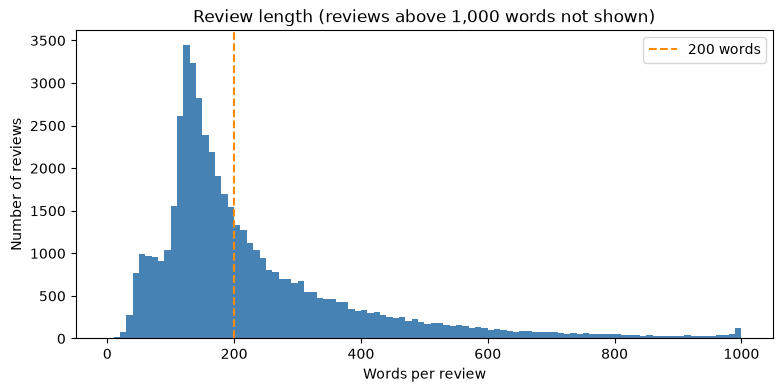

In [6]:
lengths = df["review"].str.split().str.len()
print(lengths.describe().round(1).to_string())
print(f"\nReviews longer than 200 words: {(lengths > 200).mean():.0%}")

plt.figure(figsize=(9, 4))
plt.hist(lengths, bins=100, range=(0, 1000), color="steelblue")
plt.axvline(200, color="darkorange", linestyle="--", label="200 words")
plt.xlabel("Words per review")
plt.ylabel("Number of reviews")
plt.title("Review length (reviews above 1,000 words not shown)")
plt.legend()
plt.show()

The median review has 173 words, but the distribution has a long tail: about 40% of the reviews are longer than 200 words, and the longest has almost 2,500. I come back to this in Task 5.

There is also a small bump right before 1,000 words, and very few reviews after it. My guess is that IMDB limited reviews to about 1,000 words when most of these were written, so people with a lot to say wrote right up to the limit.

## Task 2 – Split the Dataset into Training and Testing

Based on what I saw above, I clean two things before splitting:

- I drop the 418 duplicate reviews.
- I replace the `<br />` tags with spaces.

Then I separate the features (the review text) from the targets (the sentiment, converted to 1 for positive and 0 for negative) and split them 60% / 40%. I use `stratify=y` so both sets keep the 50/50 balance between positive and negative reviews, and a fixed `random_state` so I get the same split every time I run the notebook.

In [7]:
n_before = len(df)
df = df.drop_duplicates(subset="review")
print(f"Removed {n_before - len(df)} duplicate reviews, {len(df):,} remain\n")

X = df["review"].str.replace(r"<br\s*/?>", " ", regex=True)
y = (df["sentiment"] == "positive").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
print(f"Training examples: {len(X_train):,}")
print(f"Testing examples:  {len(X_test):,}")

Removed 418 duplicate reviews, 49,582 remain



Training examples: 29,749
Testing examples:  19,833


## Task 3 – Count Vectorizer + Logistic Regression

I start with the simplest representation. `CountVectorizer` builds a vocabulary from the training reviews and turns each review into a vector of word counts (a bag of words). Word order is lost; only the counts remain. Logistic Regression then learns one weight per word.

I set `max_iter=1000` because with the default of 100 iterations, the solver stops before it converges on this many features.

In [8]:
count_model = evaluate(
    "Count + LR",
    make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000)),
)

Count + LR
Accuracy: 0.8857

              precision    recall  f1-score   support

    negative     0.8942    0.8741    0.8840      9879
    positive     0.8778    0.8973    0.8874      9954

    accuracy                         0.8857     19833
   macro avg     0.8860    0.8857    0.8857     19833
weighted avg     0.8859    0.8857    0.8857     19833



## Task 4 – TF-IDF Vectorizer + Logistic Regression

Raw counts treat every word the same. But a word like *movie* appears in almost every review, so it says very little about the sentiment. `TfidfTransformer` corrects this: it gives less weight to words that appear in many reviews and more weight to rarer ones. It also scales each review vector to length 1, so a long review doesn't get bigger numbers just because it has more words.

In [9]:
tfidf_model = evaluate(
    "TF-IDF + LR",
    make_pipeline(CountVectorizer(), TfidfTransformer(), LogisticRegression(max_iter=1000)),
)

TF-IDF + LR
Accuracy: 0.8926

              precision    recall  f1-score   support

    negative     0.9059    0.8752    0.8903      9879
    positive     0.8802    0.9098    0.8947      9954

    accuracy                         0.8926     19833
   macro avg     0.8930    0.8925    0.8925     19833
weighted avg     0.8930    0.8926    0.8925     19833



## Task 5 – Pretrained Word Embeddings + Logistic Regression

Here the idea changes. Instead of one feature per word, each word becomes a dense vector that represents its meaning, learned beforehand on a large amount of text.

**Pretrained model.** I use GloVe from gensim (`glove-wiki-gigaword-100`: 400,000 words, trained on Wikipedia and news articles). I chose the 100-dimensional version on purpose: with concatenation, each review becomes 200 × 100 = 20,000 numbers. With the 300-dimensional version it would be 60,000 numbers per review, about 7 GB for the training set alone, which is too much for my laptop.

**Embedding vectorizer.** A scikit-learn pipeline only accepts steps that have `fit` and `transform` methods, so I wrote `EmbeddingVectorizer`, a small class that inherits from `BaseEstimator` and `TransformerMixin`. `fit` has nothing to learn, since the embeddings are already trained. `transform` lowercases each review, splits it into words, skips the words GloVe doesn't know, and turns the rest into one vector. I try the two approaches from the assignment and keep the better one:

- **Mean:** average the vectors of all the words, giving 100 numbers per review.
- **Concatenation:** place the vectors of the first 200 words one after another, padding with zeros when the review is shorter, giving 20,000 numbers per review.

In [10]:
TOKEN_PATTERN = re.compile(r"[a-z]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())


class EmbeddingVectorizer(BaseEstimator, TransformerMixin):
    """Turn each review into a vector using word embeddings (gensim KeyedVectors)."""

    def __init__(self, embeddings, method="mean", max_words=200):
        self.embeddings = embeddings
        self.method = method
        self.max_words = max_words

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        dim = self.embeddings.vector_size
        n_features = dim if self.method == "mean" else dim * self.max_words
        vectors = np.zeros((len(X), n_features), dtype=np.float32)
        for i, text in enumerate(X):
            words = [w for w in tokenize(text) if w in self.embeddings]
            if not words:
                continue
            if self.method == "mean":
                vectors[i] = self.embeddings[words].mean(axis=0)
            else:
                words = words[: self.max_words]
                vectors[i, : len(words) * dim] = self.embeddings[words].ravel()
        return vectors


glove = api.load("glove-wiki-gigaword-100")
print(f"GloVe: {len(glove):,} words, {glove.vector_size} dimensions\n")

for method in ["mean", "concat"]:
    evaluate(
        f"GloVe {method} + LR",
        make_pipeline(EmbeddingVectorizer(glove, method), LogisticRegression(max_iter=1000)),
    )
    print("-" * 60)

best = max(["mean", "concat"], key=lambda m: results[f"GloVe {m} + LR"])
print(f"Best approach with GloVe: {best}")

GloVe: 400,000 words, 100 dimensions



GloVe mean + LR
Accuracy: 0.7985

              precision    recall  f1-score   support

    negative     0.7964    0.8000    0.7982      9879
    positive     0.8006    0.7970    0.7988      9954

    accuracy                         0.7985     19833
   macro avg     0.7985    0.7985    0.7985     19833
weighted avg     0.7985    0.7985    0.7985     19833

------------------------------------------------------------


GloVe concat + LR
Accuracy: 0.6836

              precision    recall  f1-score   support

    negative     0.6834    0.6795    0.6815      9879
    positive     0.6837    0.6876    0.6856      9954

    accuracy                         0.6836     19833
   macro avg     0.6836    0.6835    0.6835     19833
weighted avg     0.6836    0.6836    0.6836     19833

------------------------------------------------------------
Best approach with GloVe: mean


## Task 6 – Own Word2Vec Embeddings + Logistic Regression

Now I train my own word2vec model (CBOW, gensim's default) on the IMDB reviews. I train it on the **training set only**, so the test reviews stay completely unseen, like in the other tasks.

I keep 100 dimensions so the comparison with GloVe is fair, use a window of 5 words around each word, ignore words that appear fewer than 5 times, and go over the data 10 times.

Before using it, I check that the model learned something meaningful by printing the closest words to *excellent* and *boring*. Then I reuse the same `EmbeddingVectorizer` and both approaches from Task 5.

In [11]:
train_sentences = [tokenize(review) for review in X_train]

# gensim's compiled training code sometimes prints a harmless, empty
# "Exception ignored in: ...our_dot_float" message (no real exception occurs),
# so its stderr output is hidden during training only.
with redirect_stderr(io.StringIO()):
    w2v = Word2Vec(
        train_sentences,
        vector_size=100,
        window=5,
        min_count=5,
        epochs=10,
        workers=4,
        seed=RANDOM_STATE,
    )
own_embeddings = w2v.wv
print(f"Own word2vec: {len(own_embeddings):,} words, {own_embeddings.vector_size} dimensions")
for word in ["excellent", "boring"]:
    similar = ", ".join(w for w, _ in own_embeddings.most_similar(word, topn=6))
    print(f"  most similar to '{word}': {similar}")
print()

for method in ["mean", "concat"]:
    evaluate(
        f"Word2Vec {method} + LR",
        make_pipeline(EmbeddingVectorizer(own_embeddings, method), LogisticRegression(max_iter=1000)),
    )
    print("-" * 60)

best = max(["mean", "concat"], key=lambda m: results[f"Word2Vec {m} + LR"])
print(f"Best approach with own word2vec: {best}")

Own word2vec: 31,467 words, 100 dimensions
  most similar to 'excellent': outstanding, exceptional, superb, terrific, amazing, incredible
  most similar to 'boring': dull, pointless, tedious, predictable, confusing, unoriginal



Word2Vec mean + LR
Accuracy: 0.8525

              precision    recall  f1-score   support

    negative     0.8573    0.8445    0.8508      9879
    positive     0.8479    0.8605    0.8542      9954

    accuracy                         0.8525     19833
   macro avg     0.8526    0.8525    0.8525     19833
weighted avg     0.8526    0.8525    0.8525     19833

------------------------------------------------------------


Word2Vec concat + LR
Accuracy: 0.7534

              precision    recall  f1-score   support

    negative     0.7536    0.7502    0.7519      9879
    positive     0.7532    0.7566    0.7549      9954

    accuracy                         0.7534     19833
   macro avg     0.7534    0.7534    0.7534     19833
weighted avg     0.7534    0.7534    0.7534     19833

------------------------------------------------------------
Best approach with own word2vec: mean


## Task 7 – Plot and Interpret the Results

One bar per model, colored by family: bag of words in blue, GloVe in orange, my own word2vec in green.

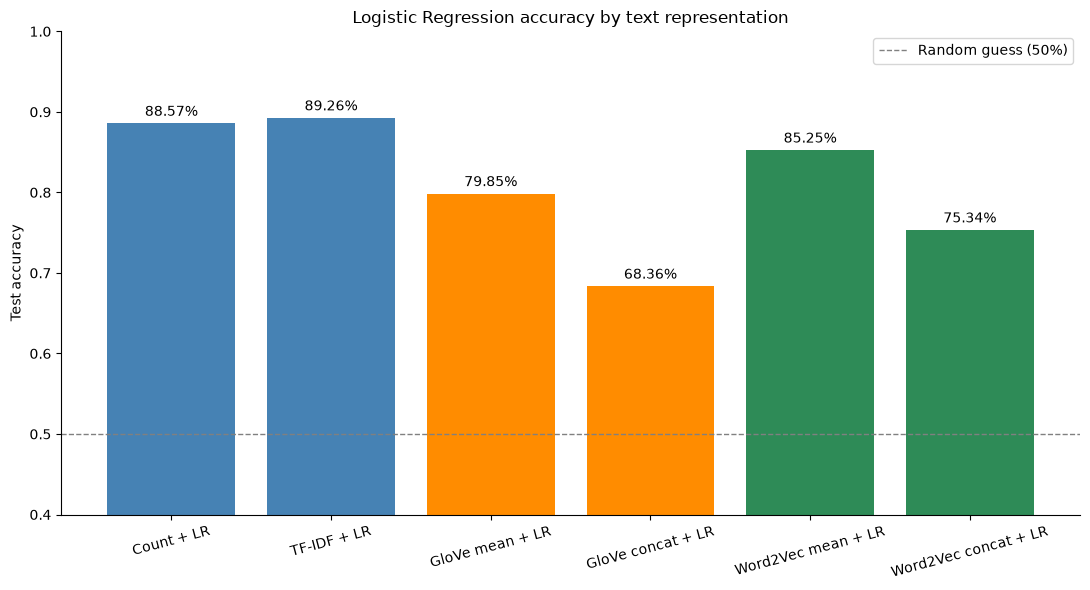

In [12]:
names = list(results)
accuracies = [results[n] for n in names]
colors = ["steelblue", "steelblue", "darkorange", "darkorange", "seagreen", "seagreen"]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(names, accuracies, color=colors)
ax.bar_label(bars, labels=[f"{a:.2%}" for a in accuracies], padding=3)
ax.set_ylim(0.4, 1.0)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Random guess (50%)")
ax.legend(loc="upper right")
ax.set_ylabel("Test accuracy")
ax.set_title("Logistic Regression accuracy by text representation")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### What the results show

*The y-axis starts at 40% so the differences are easier to see. The dashed line is a random guess (50%, since the classes are balanced). My word2vec results can move by about 0.1% between runs, because gensim trains with several threads and that is not exactly reproducible.*

**The simplest models win.** TF-IDF is the best (89.3%), just ahead of plain counts (88.6%). I think the reason is the way people express sentiment in reviews: through specific words like *excellent*, *worst*, *waste* or *masterpiece*. With a bag of words, each of the ~83,000 words in the vocabulary gets its own weight, so the model can pick these words up directly. TF-IDF adds 0.7 points on top, by lowering the weight of words that are everywhere (*movie*, *film*) and by putting long and short reviews on the same scale.

**Averaging embeddings loses information.** With averaging, a review of about 230 words becomes just 100 numbers. The few words that carry the opinion get mixed with all the neutral words about the plot and the actors, and their signal is diluted. There is a second problem I didn't expect: embeddings put words close together when they appear in similar contexts, and opposite opinions appear in exactly the same contexts. In GloVe, the 2nd closest word to *bad* is *good* (similarity 0.77). So a positive and a negative review can end up with similar averages.

**My own embeddings beat GloVe by more than 5 points (about 85% vs 79.9%).** GloVe learned its vectors from Wikipedia and news, not from people talking about movies. My word2vec model learned from the reviews themselves, and it shows: its closest words to *boring* include *dull*, *pointless*, *tedious* and *predictable*, exactly how reviewers write. It knows only 31,000 words against GloVe's 400,000, but they are the right words for this task.

**Concatenation is the worst approach for both (68.4% with GloVe, about 75% with my word2vec).** The problem is position. *Excellent* as the 3rd word and *excellent* as the 50th word land on completely different features, so the model has to learn the effect of each word separately for each of the 200 positions: 20,000 features for only about 30,000 training reviews. On top of that, as I saw when exploring the data, about 40% of the reviews are longer than 200 words, so their ending is cut off, and that is often where the reviewer gives the final verdict. To really use word order, a sequence model (RNN, LSTM or transformer) would be needed.

**Conclusion.** For a linear classifier on this dataset, TF-IDF is the best choice: the most accurate, and also the simplest and fastest to train. Word embeddings only start to compete when they are trained on the same kind of text, and even then, averaging them throws away too much to beat a plain bag of words.